In [1]:
import torch

print("="*50)

print("PyTorch Version :", torch.__version__)

print("CUDA Available :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA Version :", torch.version.cuda)
    print("GPU :", torch.cuda.get_device_name(0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using Device :", device)

print("="*50)

PyTorch Version : 2.6.0+cu124
CUDA Available : True
CUDA Version : 12.4
GPU : NVIDIA GeForce GTX 1650
Using Device : cuda


In [2]:
!pip install timm tqdm seaborn scikit-learn opencv-python

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models
from torchvision.datasets import ImageFolder
from torchvision import transforms

from torch.utils.data import DataLoader

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [4]:
dataset_path = "./datasets/imagenet-mini"

print(dataset_path)

./datasets/imagenet-mini


In [5]:
train_transform = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [6]:
train_dataset = ImageFolder(
    root=os.path.join(dataset_path, "train"),
    transform=train_transform
)

val_dataset = ImageFolder(
    root=os.path.join(dataset_path, "val"),
    transform=test_transform
)

print("Training Images :", len(train_dataset))
print("Validation Images :", len(val_dataset))

Training Images : 34745
Validation Images : 3923


In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [8]:
classes = train_dataset.classes

print("="*60)
print("Number of Classes :", len(classes))
print("First 10 Classes:")
print(classes[:10])
print("="*60)

Number of Classes : 1000
First 10 Classes:
['n01440764', 'n01443537', 'n01484850', 'n01491361', 'n01494475', 'n01496331', 'n01498041', 'n01514668', 'n01514859', 'n01518878']


In [9]:
print(len(classes))

1000


In [10]:
model = models.resnet50(
    weights=models.ResNet50_Weights.IMAGENET1K_V2
)

model = model.to(device)

print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [11]:
for param in model.parameters():
    param.requires_grad = False

for param in model.layer4.parameters():
    param.requires_grad = True

In [12]:
model.fc = nn.Linear(
    model.fc.in_features,
    1000
)

model = model.to(device)

print(model.fc)

Linear(in_features=2048, out_features=1000, bias=True)


In [13]:
trainable = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

total = sum(
    p.numel() for p in model.parameters()
)

print("="*50)
print(f"Trainable Parameters : {trainable:,}")
print(f"Total Parameters     : {total:,}")
print("="*50)

Trainable Parameters : 17,013,736
Total Parameters     : 25,557,032


In [14]:
criterion = nn.CrossEntropyLoss()

In [15]:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad,
           model.parameters()),
    lr=1e-4,
    weight_decay=1e-4
)

In [16]:
scheduler = torch.optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

In [17]:
print("="*60)

print("Model Ready")

print("="*60)

print(model)

print("\nDevice :", device)

print("\nOptimizer :")
print(optimizer)

print("\nLoss Function :")
print(criterion)

print("="*60)

Model Ready
ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1),

In [18]:
def train(model, loader, optimizer, criterion):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [19]:
def validate(model, loader, criterion):

    model.eval()

    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)
    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [21]:
epochs = 25

train_losses = []
val_losses = []

train_accs = []
val_accs = []

best_acc = 0

best_epoch = 0

best_train_loss = 0
best_val_loss = 0

best_train_acc = 0
best_val_acc = 0

os.makedirs("./models", exist_ok=True)

for epoch in range(epochs):

    print(f"\nEpoch {epoch+1}/{epochs}")

    train_loss, train_acc = train(
        model,
        train_loader,
        optimizer,
        criterion
    )

    val_loss, val_acc = validate(
        model,
        val_loader,
        criterion
    )

    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.2f}%")

    print(f"Validation Loss : {val_loss:.4f}")
    print(f"Validation Accuracy : {val_acc:.2f}%")

    print(f"Learning Rate : {scheduler.get_last_lr()[0]:.8f}")

    if val_acc > best_acc:

        best_acc = val_acc
        best_epoch = epoch + 1

        best_train_loss = train_loss
        best_val_loss = val_loss

        best_train_acc = train_acc
        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "./models/best_resnet50_imagenetmini.pth"
        )

        print("Best Model Saved")


Epoch 1/25


  0%|          | 0/1086 [00:00<?, ?it/s]

  0%|          | 0/123 [00:00<?, ?it/s]

Train Loss : 1.6194
Train Accuracy : 64.49%
Validation Loss : 1.4149
Validation Accuracy : 65.38%
Learning Rate : 0.00010000
Best Model Saved

Epoch 2/25


  0%|          | 0/1086 [00:00<?, ?it/s]

  0%|          | 0/123 [00:00<?, ?it/s]

... (66 outputs left out)

Train Loss : 0.6828
Train Accuracy : 85.34%
Validation Loss : 1.3009
Validation Accuracy : 69.39%
Learning Rate : 0.00000000

Epoch 25/25


  0%|          | 0/1086 [00:00<?, ?it/s]

  0%|          | 0/123 [00:00<?, ?it/s]

Train Loss : 0.6768
Train Accuracy : 85.18%
Validation Loss : 1.2867
Validation Accuracy : 69.49%
Learning Rate : 0.00000000


In [22]:
loaded_model = models.resnet50(weights=None)

loaded_model.fc = nn.Linear(
    loaded_model.fc.in_features,
    1000
)

loaded_model.load_state_dict(
    torch.load(
        "./models/best_resnet50_imagenetmini.pth",
        map_location=device
    )
)

loaded_model = loaded_model.to(device)

loaded_model.eval()

print("Best Model Loaded Successfully!")

Best Model Loaded Successfully!


In [23]:
all_preds = []
all_labels = []

with torch.no_grad():

    for images, labels in tqdm(val_loader):

        images = images.to(device)
        labels = labels.to(device)

        outputs = loaded_model(images)

        _, preds = torch.max(outputs,1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("Prediction Completed")

  0%|          | 0/123 [00:00<?, ?it/s]

Prediction Completed


In [24]:
accuracy = accuracy_score(
    all_labels,
    all_preds
)

precision = precision_score(
    all_labels,
    all_preds,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    average="weighted",
    zero_division=0
)

In [25]:
print("="*60)
print("Best ResNet50 ImageNet Mini Performance")
print("="*60)

print(f"Best Epoch      : {best_epoch}")

print(f"Train Loss      : {best_train_loss:.4f}")
print(f"Train Accuracy  : {best_train_acc:.2f}%")

print(f"Validation Loss : {best_val_loss:.4f}")
print(f"Validation Accuracy : {best_val_acc:.2f}%")

print(f"Precision       : {precision*100:.2f}%")
print(f"Recall          : {recall*100:.2f}%")
print(f"F1 Score        : {f1*100:.2f}%")

print("="*60)

Best ResNet50 ImageNet Mini Performance
Best Epoch      : 22
Train Loss      : 0.6758
Train Accuracy  : 85.45%
Validation Loss : 1.2882
Validation Accuracy : 69.72%
Precision       : 73.80%
Recall          : 69.72%
F1 Score        : 69.17%


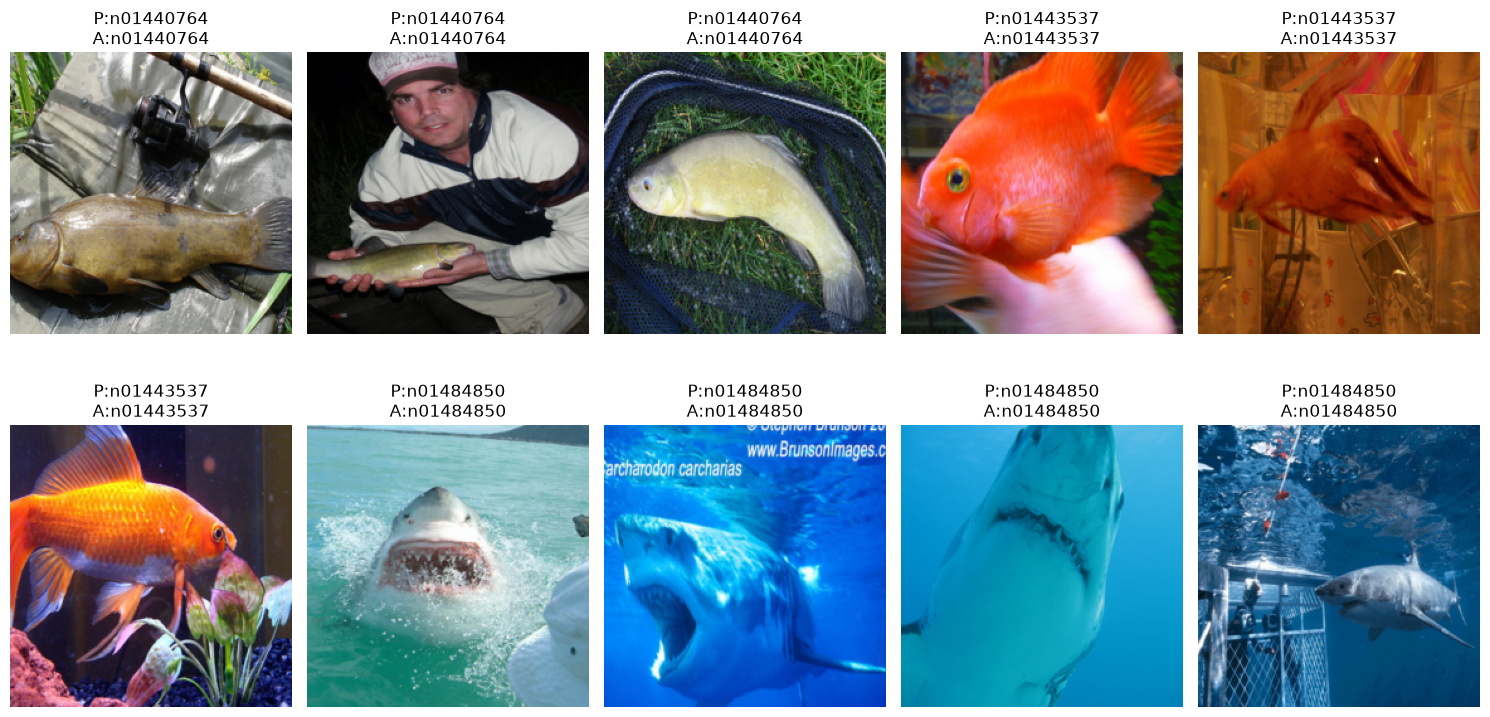

In [26]:
images, labels = next(iter(val_loader))

images_gpu = images.to(device)

with torch.no_grad():

    outputs = loaded_model(images_gpu)

    _, predicted = torch.max(outputs,1)

plt.figure(figsize=(15,8))

for i in range(10):

    plt.subplot(2,5,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(
        f"P:{classes[predicted[i].item()]}\nA:{classes[labels[i].item()]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

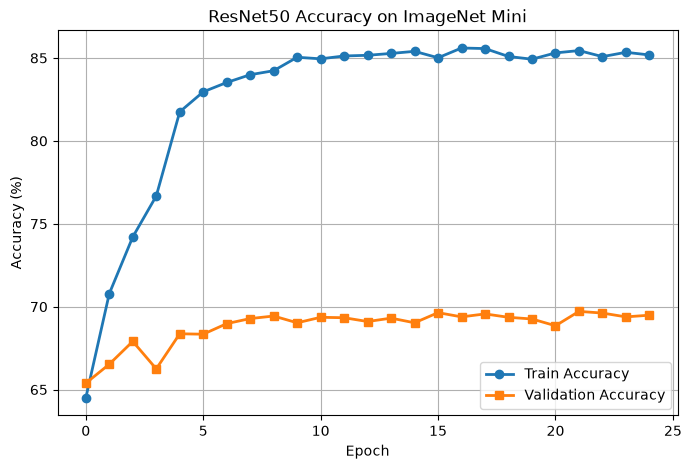

In [27]:
plt.figure(figsize=(8,5))

plt.plot(train_accs, marker='o', linewidth=2, label='Train Accuracy')
plt.plot(val_accs, marker='s', linewidth=2, label='Validation Accuracy')

plt.title("ResNet50 Accuracy on ImageNet Mini")

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")

plt.grid(True)
plt.legend()

plt.show()

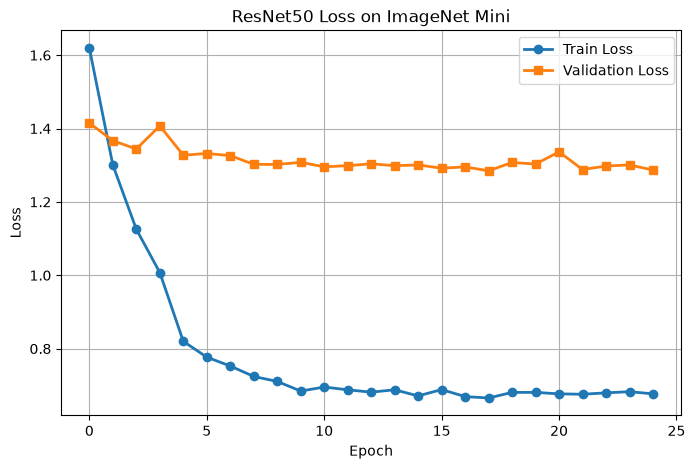

In [28]:
plt.figure(figsize=(8,5))

plt.plot(train_losses, marker='o', linewidth=2, label='Train Loss')
plt.plot(val_losses, marker='s', linewidth=2, label='Validation Loss')

plt.title("ResNet50 Loss on ImageNet Mini")

plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.grid(True)
plt.legend()

plt.show()